# ID-Pose + EscherNet: current progress

This is a record of what I have working so far, the tests I ran, and the main problem I still need to solve. The notebook only reads saved outputs, it does not run either diffusion model.


## 1. Current status

| Part | Result so far |
|---|---|
| ID-Pose | Pose estimation now runs in FP16 on my 4 GB GPU |
| EscherNet 6DoF | Joint `T_out=4` generation works at 256×256 (7.4 seconds, 2.034 GiB peak allocated VRAM) |
| Connection between them | I can convert ID-Pose's `rel_sph` output to camera matrices and pass them to EscherNet |
| Zero-pose check | EscherNet produces something close to the input view |
| $180^\circ$ rear-view check | The output breaks down badly |

### Summary

The complete path runs and the first result contains a recognizable lion and parts of the original laboratory scene. It is still geometrically poor, especially for a large change in viewpoint.

My next test will use the known camera poses for the GSO elephant views `000 -> 015` (about $32.5^\circ$ apart). That should make it easier to tell whether an error comes from ID-Pose, my conversion, or EscherNet


In [30]:
# Helper cell - root directory finder

import json
import subprocess
from IPython.display import Image, Markdown, display
from pathlib import Path


def locate_root():
    cwd = Path.cwd().resolve()
    candidates = [cwd, cwd.parent]
    for candidate in candidates:
        if (candidate / 'id-pose').is_dir() and (candidate / 'EscherNet').is_dir():
            return candidate
    raise FileNotFoundError(
        'Could not locate the thesis root. Start Jupyter from the directory containing id-pose/ and EscherNet/.'
    )


ROOT = locate_root()
print(f'Thesis root: {ROOT}')


Thesis root: /home/ayush/development/thesis


### Git state

Print the branch, commit, and local changes here so the results can be tied to the code that produced them


In [22]:
def git_value(repo, *args):
    result = subprocess.run(
        ['/usr/bin/git', '-C', str(repo), *args],
        text=True, capture_output=True, check=False,
    )
    return result.stdout.strip() if result.returncode == 0 else f'ERROR: {result.stderr.strip()}'


for name in ['id-pose', 'EscherNet']:
    repo = ROOT / name
    print(f'[{name}]')
    print('branch:', git_value(repo, 'branch', '--show-current'))
    print('commit:', git_value(repo, 'rev-parse', 'HEAD'))
    status = git_value(repo, 'status', '--short')
    print('working tree:', 'clean' if not status else '\n' + status)
    print()


[id-pose]
branch: experiment/low-vram
commit: d74352669afb1dad3a42182528715192312d1597
working tree: 
?? outputs/lion2-8x20/
?? outputs/lion2-lowmem/
?? outputs/lion2-object/

[EscherNet]
branch: main
commit: 10b650492ba97b5104a3136de07d1a67f4ada458
working tree: 
?? CaPE.local.py
?? environment.local.yml



### Saved files used below

This is a quick check that the reports and images are present


In [ ]:
ARTIFACTS = {
    'ID-Pose full-scene pose': ROOT / 'id-pose/outputs/lion2-lowmem/lion2_000+001/pose.json',
    'ID-Pose isolated-object pose': ROOT / 'id-pose/outputs/lion2-object/lion2_000+001/pose.json',
    'EscherNet multiview report': ROOT / 'results/eschernet-multiview/report.json',
    'EscherNet multiview sheet': ROOT / 'results/eschernet-multiview/contact-sheet.png',
    'Initial integration report': ROOT / 'results/idpose-to-eschernet/report.json',
    'Initial integration comparison': ROOT / 'results/idpose-to-eschernet/comparison-000-to-001.png',
    'Isolated-object integration report': ROOT / 'results/idpose-to-eschernet-object/report.json',
    'Isolated-object comparison': ROOT / 'results/idpose-to-eschernet-object/comparison-000-to-001.png',
    'Identity control': ROOT / 'results/adapter-control-identity/comparison-000-to-001.png',
    'Manual rear control': ROOT / 'results/adapter-control-rear/comparison-000-to-001.png',
}

for label, path in ARTIFACTS.items():
    print(f"{'OK' if path.exists() else 'MISSING':7}  {label}: {path.relative_to(ROOT)}")


### ID-Pose on the laptop GPU

I made the following changes to get ID-Pose running locally:

- load the checkpoint on the CPU first
- remove unused EMA tensors and avoid constructing a second EMA model
- use FP16 weights, but keep `GroupNorm32` layers in FP32
- freeze the diffusion model because only the camera pose is optimized
- exclude frozen parameters from the checkpoint backward call

For the isolated lion I used 4 azimuth seeds, 5 adjustment iterations, and 50 refinement iterations. This is enough for a local test I think but much smaller than the full settings and not yet a proper accuracy result


In [24]:
import json
import pandas as pd
from IPython.display import display, Markdown


def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))


pose_path = ARTIFACTS["ID-Pose isolated-object pose"]

if pose_path.exists():
    pose = read_json(pose_path)

    anchor = pose["anchor_vid"]
    targets = [key for key in pose["obs"] if key != anchor]

    rows = []

    for target in targets:
        rel_sph = pose["obs"][target].get("rel_sph")

        if rel_sph is None:
            polar = azimuth = radius = "—"
        else:
            polar, azimuth, radius = (
                rf"${rel_sph[0]:.3f}$",
                rf"${rel_sph[1]:.3f}$",
                rf"${rel_sph[2]:.3f}$",
            )

        rows.append({
            "View": f"{anchor} → {target}",
            r"$\Delta\,\mathrm{polar}$": polar,
            r"$\Delta\,\mathrm{azimuth}$": azimuth,
            r"$\Delta\,\mathrm{radius}$": radius,
        })

    table = pd.DataFrame(rows)

    display(Markdown("### ID-Pose relative pose\n"))
    display(Markdown(table.to_markdown(index=False)))

else:
    print("Isolated-object ID-Pose result is missing.")

### ID-Pose relative pose


| View      | $\Delta\,\mathrm{polar}$   | $\Delta\,\mathrm{azimuth}$   | $\Delta\,\mathrm{radius}$   |
|:----------|:---------------------------|:-----------------------------|:----------------------------|
| 000 → 001 | $0.963$                    | $3.351$                      | $0.080$                     |

## EscherNet test

I used one elephant reference view and generated four target views together at `256x256`. The four views are produced in one call (`T_in=1`, `T_out=4`), so this uses the multiview path rather than four separate single view runs.


### EscherNet multiview report

| Metric              | Result                                       |
|:--------------------|:---------------------------------------------|
| Resolution          | $256 \times 256$                             |
| Views               | $T_{\mathrm{in}} = 1,\;T_{\mathrm{out}} = 4$ |
| Denoising steps     | $30$                                         |
| Elapsed time        | $7.41\,\mathrm{s}$                           |
| Peak allocated VRAM | $2.034\,\mathrm{GiB}$                        |
| Mean PSNR           | $12.18\,\mathrm{dB}$                         |
| GPU                 | NVIDIA GeForce RTX 3050 Laptop GPU           |

### Multiview results

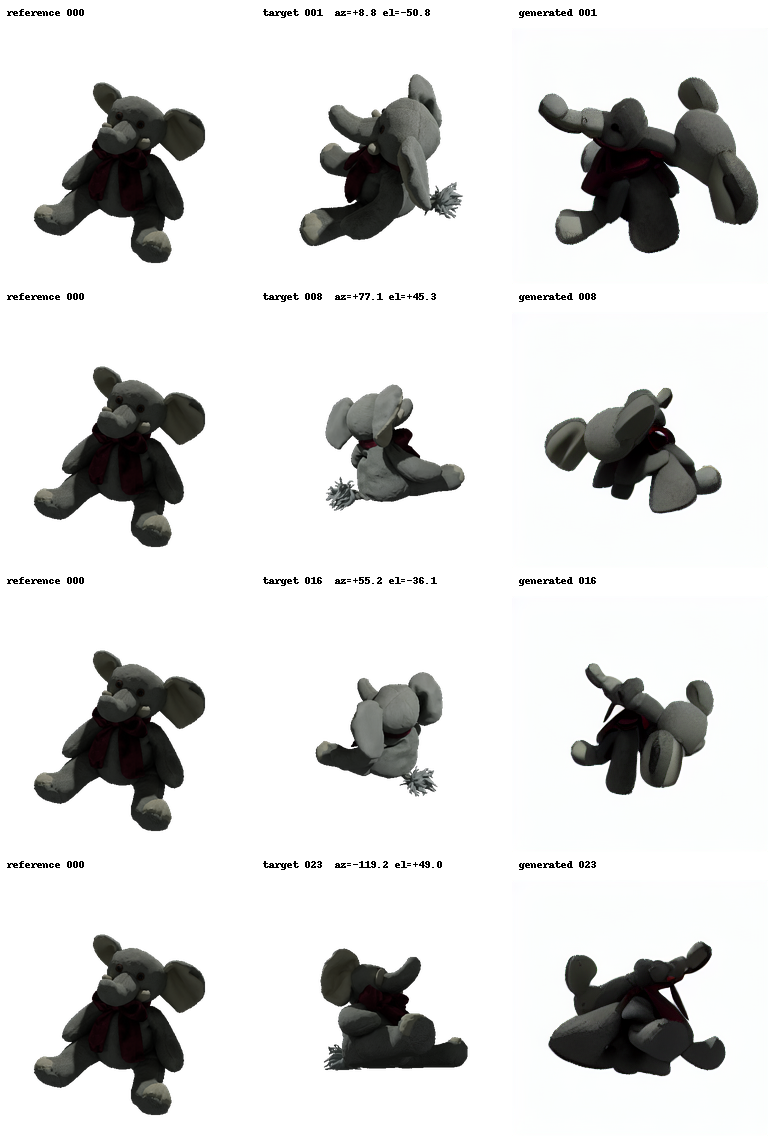

In [29]:
multiview_report = ARTIFACTS["EscherNet multiview report"]

if multiview_report.exists():
    report = read_json(multiview_report)

    rows = [
        {
            "Metric": "Resolution",
            "Result": rf"${report['resolution']} \times {report['resolution']}$",
        },
        {
            "Metric": "Views",
            "Result": (
                rf"$T_{{\mathrm{{in}}}} = {report['T_in']},\;"
                rf"T_{{\mathrm{{out}}}} = {report['T_out']}$"
            ),
        },
        {
            "Metric": "Denoising steps",
            "Result": rf"${report['steps']}$",
        },
        {
            "Metric": "Elapsed time",
            "Result": rf"${report['elapsed_seconds']:.2f}\,\mathrm{{s}}$",
        },
        {
            "Metric": "Peak allocated VRAM",
            "Result": rf"${report['peak_allocated_vram_gib']:.3f}\,\mathrm{{GiB}}$",
        },
        {
            "Metric": "Mean PSNR",
            "Result": rf"${report['mean_psnr_db']:.2f}\,\mathrm{{dB}}$",
        },
        {
            "Metric": "GPU",
            "Result": report["gpu"],
        },
    ]

    table = pd.DataFrame(rows)

    display(Markdown("### EscherNet multiview report"))
    display(Markdown(table.to_markdown(index=False)))

else:
    print("Multiview report is missing.")

sheet = ARTIFACTS["EscherNet multiview sheet"]

if sheet.exists():
    display(Markdown("### Multiview results"))
    display(Image(filename=str(sheet)))

### Converting the pose

ID-Pose returns a relative spherical displacement

$$\Delta s = [\Delta\theta,\;\Delta\phi,\;\Delta r],$$

where $\theta$ is the polar angle from the positive Z axis, $\phi$ is the azimuth in the XY plane, and $r$ is the camera radius. I currently choose an anchor $s_a$ and calculate

$$s_t = s_a + \Delta s$$

I then convert the two spherical camera centres to Cartesian coordinates:

$$c=[r\sin\theta\cos\phi,\;r\sin\theta\sin\phi,\;r\cos\theta].$$

Finally, I build Z-up look-at matrices in the same format used by EscherNet. I checked this part against the bundled GSO matrices and obtained differences below $2.4 \times 10^{-7}$.

There is still an ambiguity here: ID-Pose gives me the relative spherical displacement, but not the absolute pose of the anchor camera. For the real lion images I used a canonical anchor. I still need to test that assumption with data where the real camera matrices are known.


### First combined test

For the first run I kept the full laboratory images. The result is badly distorted, but I can still recognize the lion and some laboratory-like structures. I take this as evidence that the complete path is conditioning the output on the input image, not as evidence that the target view is correct.


### Initial integration report

| Metric                       | Result                |
|:-----------------------------|:----------------------|
| Runtime                      | $3.03\,\mathrm{s}$    |
| Peak allocated VRAM          | $2.027\,\mathrm{GiB}$ |
| PSNR against observed target | $7.58\,\mathrm{dB}$   |

### Integration comparison

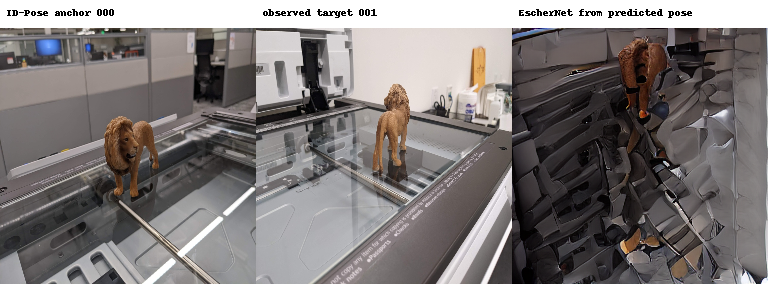

In [26]:
integration_report = ARTIFACTS["Initial integration report"]

if integration_report.exists():
    report = read_json(integration_report)

    rows = [
        {
            "Metric": "Runtime",
            "Result": rf"${report['elapsed_seconds']:.2f}\,\mathrm{{s}}$",
        },
        {
            "Metric": "Peak allocated VRAM",
            "Result": rf"${report['peak_allocated_vram_gib']:.3f}\,\mathrm{{GiB}}$",
        },
        {
            "Metric": "PSNR against observed target",
            "Result": rf"${report['psnr_db_against_observed_target']:.2f}\,\mathrm{{dB}}$",
        },
    ]

    table = pd.DataFrame(rows)

    display(Markdown("### Initial integration report"))
    display(Markdown(table.to_markdown(index=False)))

else:
    print("Initial integration report is missing.")

comparison = ARTIFACTS["Initial integration comparison"]

if comparison.exists():
    display(Markdown("### Integration comparison"))
    display(Image(filename=str(comparison)))


- The generated image contains a recognizable lion and parts that look like the lab scene.
- The geometry is heavily distorted and the lion does not match the observed rear view well.
- PSNR is misleading for these examples?. The isolated object image scores slightly higher mainly because most of the image is white, even though the lion itself looks worse. I should use a foreground mask and a perceptual metric later


 3.### Simple checks

I ran two manual poses to check whether the failure came only from ID-Pose.


### Identity control: $\Delta\mathrm{pose} = [0,\,0,\,0]$

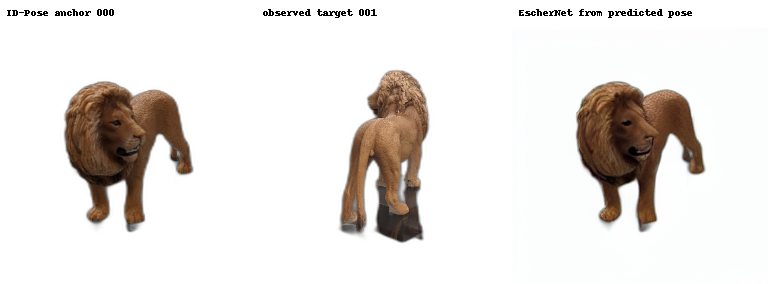

### Manual rear control: $\Delta\mathrm{pose} = [0,\,\pi,\,0]$

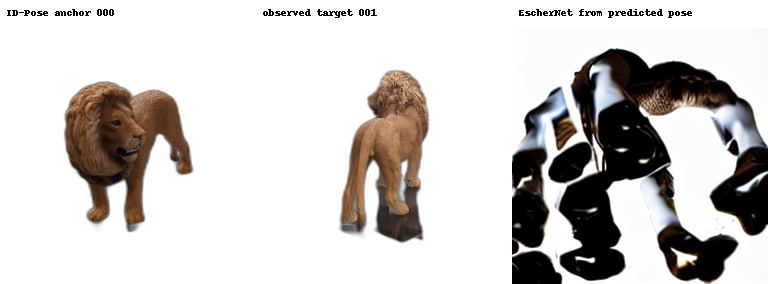

### ID-Pose estimate on isolated object

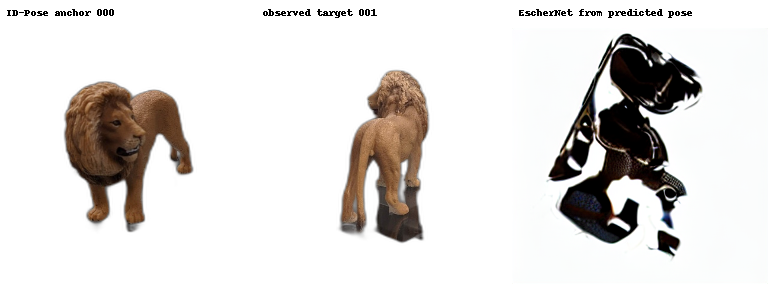

In [27]:
controls = [
    (
        r"Identity control: $\Delta\mathrm{pose} = [0,\,0,\,0]$",
        ARTIFACTS["Identity control"],
    ),
    (
        r"Manual rear control: $\Delta\mathrm{pose} = [0,\,\pi,\,0]$",
        ARTIFACTS["Manual rear control"],
    ),
    (
        "ID-Pose estimate on isolated object",
        ARTIFACTS["Isolated-object comparison"],
    ),
]

for title, path in controls:
    display(Markdown(f"### {title}"))

    if path.exists():
        display(Image(filename=str(path)))
    else:
        display(
            Markdown(
                rf"*Missing:* `{path.relative_to(ROOT)}`"
            )
        )

1. With a zero relative pose, the output looks similar to the anchor. So loading and preprocessing are basically correct.
2. A manually specified $180^\circ$ turn also fails, so the bad rear view is not only caused by ID-Pose's estimate.
3. The lion pair is a difficult front to back case with almost no shared visible surface. I will keep it as a failure example, but not use it as the main benchmark


## Commands I used

I am leaving these as text so running the notebook cannot accidentally launch either model.

### ID-Pose local run

```bash
cd /home/ayush/development/thesis/id-pose

PYTORCH_CUDA_ALLOC_CONF=max_split_size_mb:64 \
micromamba run -n idpose \
python test_pose_estimation.py \
    --input data/demo/lion2 \
    --output outputs/lion2-object \
    --ckpt_path ckpts/zero123-xl-fp16.ckpt \
    --low_vram \
    --seed_cand_num 4 \
    --probe_bsz 1 \
    --adjust_iters 5 \
    --adjust_bsz 1 \
    --refine_iters 50 \
    --refine_bsz 1 \
    --explore_type pairwise \
    --refine_type pairwise \
    --est_elev none \
    --overwrite
```

### EscherNet multi-view test

```bash
cd /home/ayush/development/thesis

PYTORCH_CUDA_ALLOC_CONF=max_split_size_mb:64 \
micromamba run -n eschernet \
python scripts/05-eschernet-multiview.py
```

### Combined run

```bash
cd /home/ayush/development/thesis

PYTORCH_CUDA_ALLOC_CONF=max_split_size_mb:64 \
micromamba run -n eschernet \
python scripts/06-idpose-to-eschernet.py \
    --pose-json id-pose/outputs/lion2-object/lion2_000+001/pose.json \
    --steps 50 \
    --output-dir results/idpose-to-eschernet-object
```


## Next test

I will use the bundled GSO elephant pair `000 → 015`. The camera poses are known and the views are about $32.5^\circ$ apart, so this is a much cleaner test than the front-to-back lion pair

For this pair I will compare:

1. EscherNet using the ground truth target pose.
2. ID-Pose's `rel_sph` estimate against the ground truth relative spherical displacement.
3. EscherNet using the camera matrix derived from the ID-Pose estimate.
4. Foreground-aware PSNR/SSIM and a perceptual metric for the two generated results.

This should show whether the largest error comes from pose estimation, my conversion, or EscherNet. After that I can run a larger evaluation on the GPU cluster.
